# Figure 2c. Disease heritability of TransMap annotations

S-LDSC heritability enrichment, marginal τ* and joint τ* of the TransMap-eGene, TransMap-local and TransMap-global annotations, each conditional on the baseline-LD model, meta-analyzed across 57 traits and across the 18 brain-related and 22 blood-related subsets. Error bars are est ± 1.9 × SE, as in the original figure code; red asterisks mark P < 0.05 with a positive estimate.

Input: `data/Figure_2c_sldsc_transmap.rds`.

In [1]:
library(ggplot2)
library(patchwork)
res <- readRDS("data/Figure_2c_sldsc_transmap.rds")
res

metric,trait,annotation,est,se,pvalue
<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>
Enrichment,All traits (57),TransMap-eGene,2.747893578,0.12634006,2.873073e-19
Enrichment,All traits (57),TransMap-local,2.880688380,0.13918483,4.253659e-16
Enrichment,All traits (57),TransMap-global,1.190733355,0.53509178,7.989841e-01
Enrichment,Blood-related traits (22),TransMap-eGene,2.199174917,0.20218880,1.436264e-04
Enrichment,Blood-related traits (22),TransMap-local,2.620053102,0.26007492,2.896798e-04
Enrichment,Blood-related traits (22),TransMap-global,0.297337308,1.13336691,2.004182e-01
Enrichment,Brain-related traits (18),TransMap-eGene,3.435609946,0.16862553,4.182436e-11
Enrichment,Brain-related traits (18),TransMap-local,3.003577316,0.26800554,7.999808e-08
Enrichment,Brain-related traits (18),TransMap-global,1.860727919,0.96946576,2.213935e-01


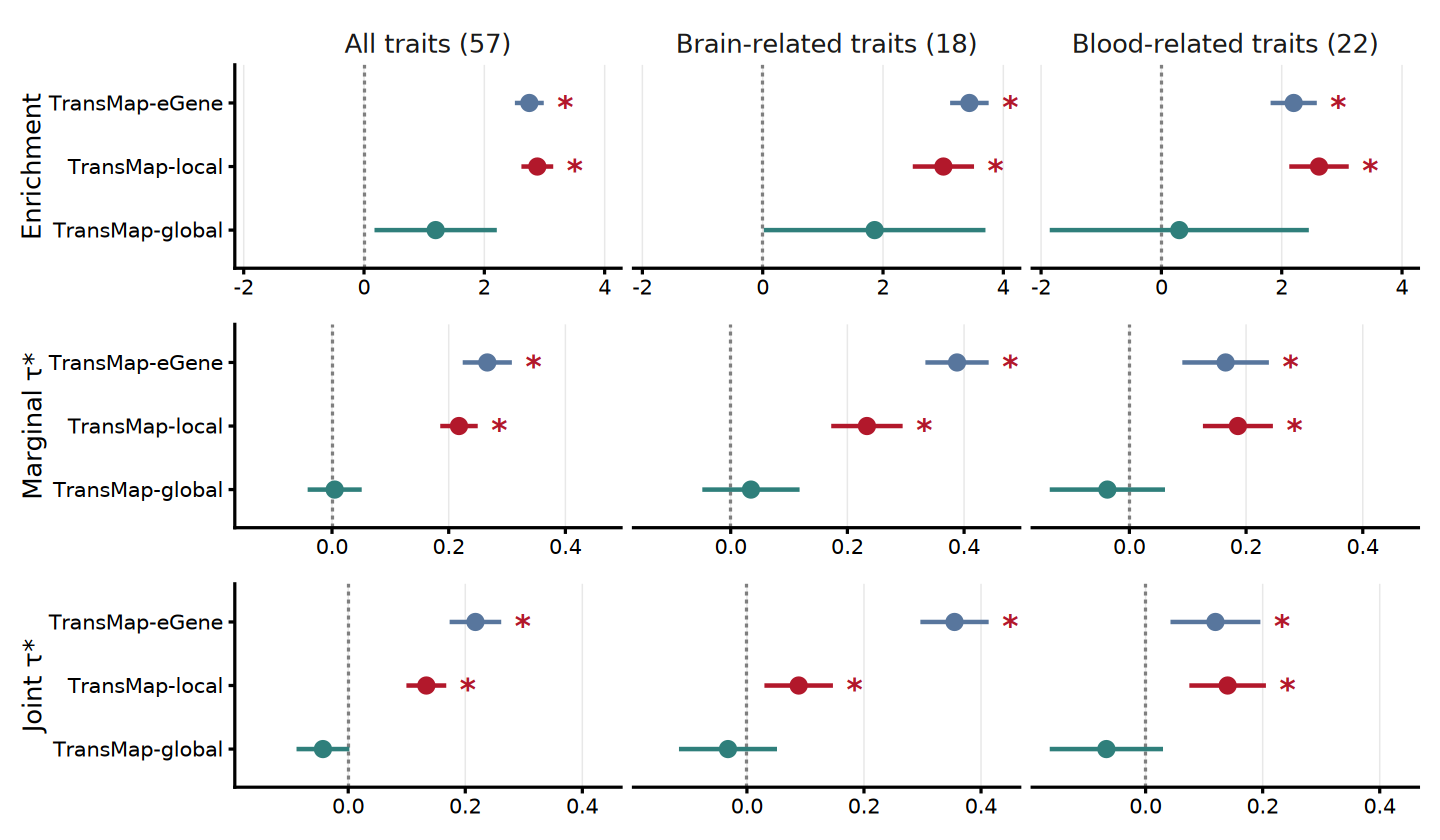

In [2]:
colors <- c("TransMap-eGene" = "#58769D", "TransMap-local" = "#B2182B", "TransMap-global" = "#2F7F7B")
res$annotation <- factor(res$annotation, levels = rev(levels(res$annotation)))
res$ci_low  <- res$est - 1.9 * res$se
res$ci_high <- res$est + 1.9 * res$se
res$star    <- ifelse(res$pvalue < 0.05 & res$est > 0, "*", "")

metric_titles <- list("Enrichment" = "Enrichment",
                      "Marginal tau*" = expression(paste("Marginal ", tau, "*")),
                      "Joint tau*" = expression(paste("Joint ", tau, "*")))

make_row <- function(m, show_strip) {
  d <- res[res$metric == m, ]
  pad <- 0.04 * diff(range(c(d$ci_low, d$ci_high, 0)))
  p <- ggplot(d, aes(y = annotation, colour = annotation)) +
    geom_vline(xintercept = 0, linetype = "dashed", colour = "grey50") +
    geom_errorbar(aes(xmin = ci_low, xmax = ci_high), width = 0, orientation = "y", linewidth = 0.95) +
    geom_point(aes(x = est), size = 3.8) +
    geom_text(aes(x = ci_high + pad, label = star), colour = "#B2182B",
              size = 6.4, fontface = "bold", hjust = 0, vjust = 0.65) +
    facet_wrap(~ trait, nrow = 1) +
    scale_colour_manual(values = colors, guide = "none") +
    labs(x = NULL, y = metric_titles[[m]]) +
    theme_classic(base_size = 15) +
    theme(strip.background = element_blank(), strip.text = element_text(size = 15),
          panel.grid.major.x = element_line(colour = "grey91", linewidth = 0.32))
  if (!show_strip) p <- p + theme(strip.text = element_blank())
  p
}

p <- make_row("Enrichment", TRUE) / make_row("Marginal tau*", FALSE) / make_row("Joint tau*", FALSE)
options(repr.plot.width = 12, repr.plot.height = 7)
p